### 实验1 神经网络原理与实现 (神经网络实现手写数字识别)
#### 一、基本实现过程

In [272]:
import random
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split
# 标准化
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
# 优化器
import torch.optim as optim

In [273]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

In [274]:
torch.set_num_threads(4)

In [275]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [276]:
# 观察数据集都有哪些文件
data = np.load('mnist.npz')
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [277]:
# 导入数据，并观察数据形状
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']
print(f"训练集特征形状: {x_train.shape}")
print(f"训练集标签形状: {y_train.shape}")
print(f"测试集特征形状: {x_test.shape}")
print(f"测试集标签形状: {y_test.shape}")

训练集特征形状: (60000, 28, 28)
训练集标签形状: (60000,)
测试集特征形状: (10000, 28, 28)
测试集标签形状: (10000,)


In [278]:
# 将单条标签数据转变为一维张量
x_train = x_train.reshape((60000, 28 * 28))
x_test = x_test.reshape((10000, 28 * 28))
print(f"训练集特征形状: {x_train.shape}")
print(f"测试集特征形状: {x_test.shape}")

# 数据范围仅[0, 255]，故除以255即可归一化
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# 另外，torch框架下，无需对无序类别标签作one-hot处理

训练集特征形状: (60000, 784)
测试集特征形状: (10000, 784)


In [279]:
# 将特征、标签等数据，转换为torch中的张量
x_train_tensor = torch.tensor(x_train, dtype = torch.float32)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32)

y_train_tensor = torch.tensor(y_train, dtype = torch.long) # 无序类别标签，类型必须是torch.long
y_test_tensor = torch.tensor(y_test, dtype = torch.long)

模型与训练参数汇总：
| 参数 | 值 |
| :---: | :---: |
| 输入层 | 28*28=784 |
| 隐藏层 | 512 |
| 输出层 | 10 |
| 激活函数 | relu |
| dropout | 不设置 |
| epoch | 20 |
| batch | 128 |
| 学习率 | 0.001 |
| 优化器 | RMSprop |
| loss函数 | 交叉熵损失 |

In [280]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

In [281]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

In [282]:
# 训练模型
def train_model(model, epochs, batch):
    # 全数据集分batch
    g = torch.Generator()
    g.manual_seed(42) # 为了可复现，为batch划分也设置固定随机种子
    
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
    train_dataloader = DataLoader(train_dataset, batch_size=batch, shuffle=True, generator=g)
    
    model.train() # 设置为训练模式

    loss_result = []

    for epoch in range(epochs):
        total_loss = 0.0  # 记录每个epoch的总损失
        batch_count = 0   # 记录该epoch的总batch数

        for batch_x, batch_y in train_dataloader:
            optimizer.zero_grad() # 梯度清零
            preds_y = model(batch_x) # 前向传播
            loss_train = criterion(preds_y, batch_y) # 计算损失
            loss_train.backward() # 反向传播（自动求导 并 累加梯度）
            optimizer.step() # 根据求导计算出的 梯度，更新模型参数

            total_loss += loss_train.item()
            batch_count += 1
        
        loss_result.append(total_loss / batch_count) # 记录损失
        print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {total_loss / batch_count:.4f}")

    return loss_result

In [283]:
loss_result = train_model(model, epochs=20, batch = 128)

训练进度: 1/20, 训练集loss: 0.2550
训练进度: 2/20, 训练集loss: 0.1078
训练进度: 3/20, 训练集loss: 0.0707
训练进度: 4/20, 训练集loss: 0.0499
训练进度: 5/20, 训练集loss: 0.0367
训练进度: 6/20, 训练集loss: 0.0263
训练进度: 7/20, 训练集loss: 0.0212
训练进度: 8/20, 训练集loss: 0.0148
训练进度: 9/20, 训练集loss: 0.0125
训练进度: 10/20, 训练集loss: 0.0093
训练进度: 11/20, 训练集loss: 0.0074
训练进度: 12/20, 训练集loss: 0.0057
训练进度: 13/20, 训练集loss: 0.0052
训练进度: 14/20, 训练集loss: 0.0042
训练进度: 15/20, 训练集loss: 0.0041
训练进度: 16/20, 训练集loss: 0.0031
训练进度: 17/20, 训练集loss: 0.0031
训练进度: 18/20, 训练集loss: 0.0022
训练进度: 19/20, 训练集loss: 0.0026
训练进度: 20/20, 训练集loss: 0.0016


In [284]:
# 绘制loss曲线，查看收敛情况
def plot_loss_curve(title, result):
    plt.figure(figsize=(8, 5))  # 设置画布大小，宽8，高5
    plt.plot(result, label='Training Loss', color='blue', linewidth=2)

    # 添加标签
    plt.title(title, fontsize=14)
    plt.xlabel('Epoch (训练轮数)', fontsize=12)
    plt.ylabel('Loss (损失值)', fontsize=12)

    plt.grid(True, linestyle='--', alpha=0.6)  # 添加网格线，方便看数值
    plt.legend(fontsize=12)  # 显示图例

    plt.show()

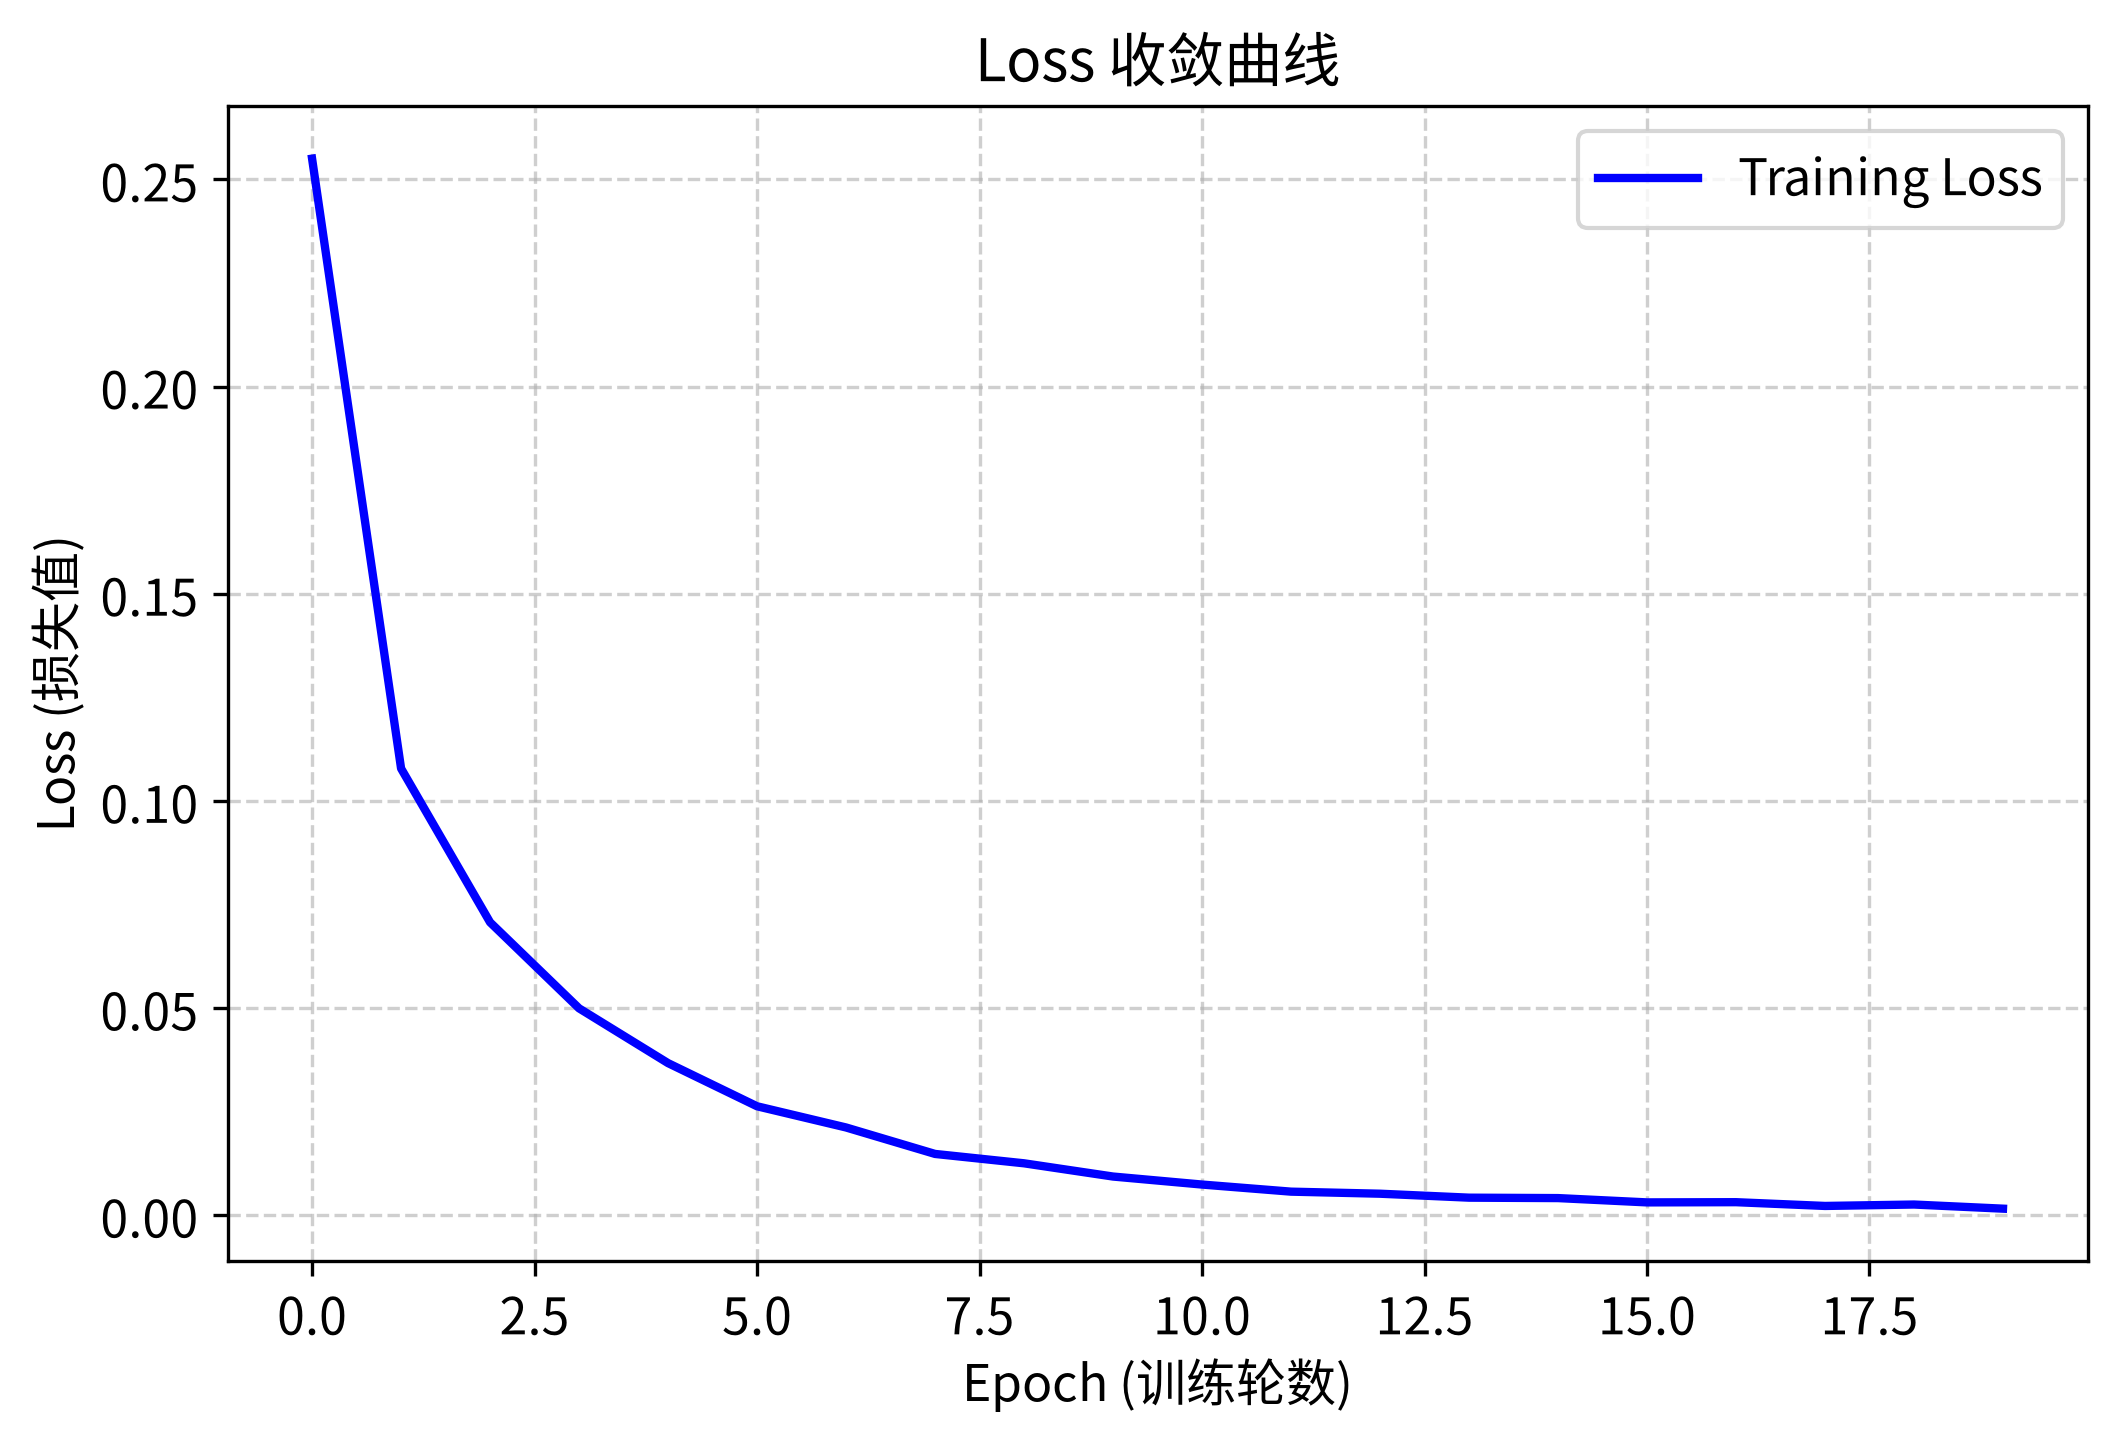

In [285]:
plot_loss_curve('Loss 收敛曲线', loss_result)

In [286]:
# 测试与评估模型
def evaluate_model(model, batch):
    model.eval() # 将模型切换到测试状态
    test_correct = 0
    test_total = 0
    test_total_loss_sum = 0.0

    # 同样分batch进行测试
    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

    with torch.no_grad(): # 关闭梯度计算，节省内存
        for batch_x, batch_y in test_dataloader:
            test_preds = model(batch_x) # 前向传播
            loss = criterion(test_preds, batch_y) # 计算单batch的平均loss
            test_total_loss_sum += loss.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            
            predicted_classes = torch.argmax(test_preds, dim=1)
            test_correct += (predicted_classes == batch_y).sum().item()
            test_total += batch_y.size(0)

    avg_test_loss = test_total_loss_sum / test_total  # 计算总平均loss
    accuracy = test_correct / test_total    # 计算Acc

    print(f"测试集平均损失 (loss): {avg_test_loss:.4f}")
    print(f"测试集准确率 (Acc): {accuracy * 100:.2f}%  ({test_correct}/{test_total})")

In [287]:
evaluate_model(model, batch=128)

测试集平均损失 (loss): 0.0823
测试集准确率 (Acc): 98.31%  (9831/10000)


#### 二、参数调整与对比
##### 2.1 隐藏层数

将隐藏层数调整为2，并定义两个隐藏层的结构一致。

In [ ]:
# 两个隐藏层的网络结构
class MultipleHiddenNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层1 512
        self.fc2 = nn.Linear(512, 512) # 隐藏层1 512 -> 隐藏层2 512
        self.out = nn.Linear(512, 10) # 隐藏层2 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 直接输出线性结果
        return x

训练进度: 1/20, 训练集loss: 0.2331
训练进度: 2/20, 训练集loss: 0.0852
训练进度: 3/20, 训练集loss: 0.0551
训练进度: 4/20, 训练集loss: 0.0407
训练进度: 5/20, 训练集loss: 0.0283
训练进度: 6/20, 训练集loss: 0.0233
训练进度: 7/20, 训练集loss: 0.0204
训练进度: 8/20, 训练集loss: 0.0147
训练进度: 9/20, 训练集loss: 0.0135
训练进度: 10/20, 训练集loss: 0.0135
训练进度: 11/20, 训练集loss: 0.0092
训练进度: 12/20, 训练集loss: 0.0109
训练进度: 13/20, 训练集loss: 0.0102
训练进度: 14/20, 训练集loss: 0.0072
训练进度: 15/20, 训练集loss: 0.0084
训练进度: 16/20, 训练集loss: 0.0064
训练进度: 17/20, 训练集loss: 0.0099
训练进度: 18/20, 训练集loss: 0.0060
训练进度: 19/20, 训练集loss: 0.0063
训练进度: 20/20, 训练集loss: 0.0065


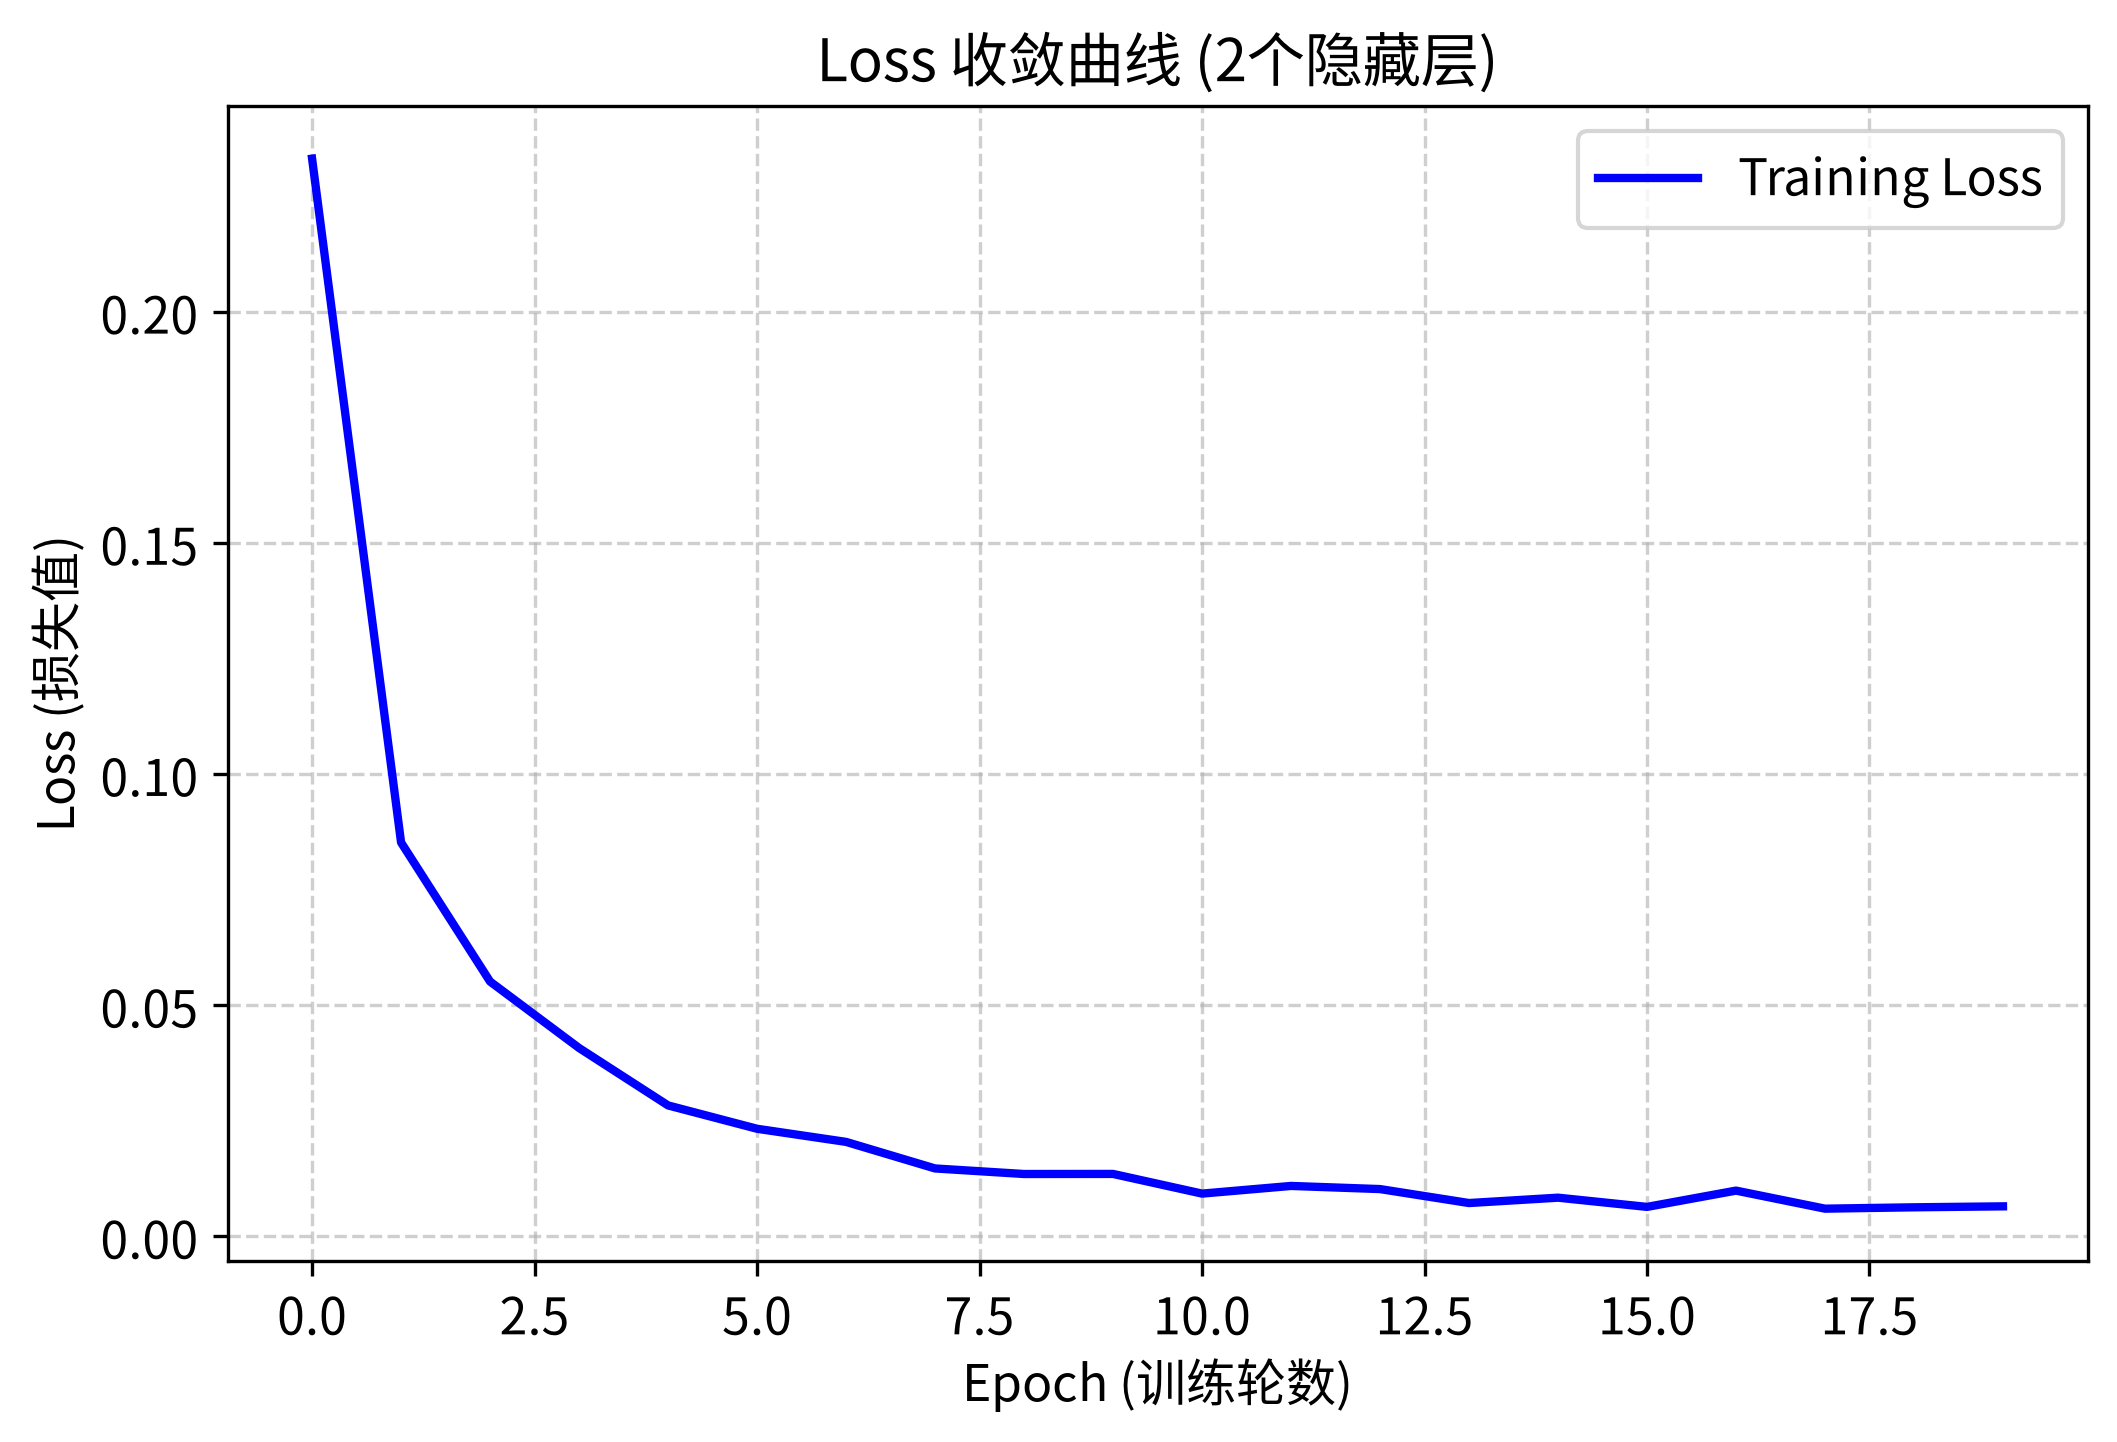

测试集平均损失 (loss): 0.1217
测试集准确率 (Acc): 98.29%  (9829/10000)


In [291]:
model = MultipleHiddenNet() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

loss_result = train_model(model, epochs=20, batch = 128)
plot_loss_curve('Loss 收敛曲线 (2个隐藏层)', loss_result)
evaluate_model(model, batch=128)

##### 2.2 隐藏层单元

In [292]:
# 可调整隐藏层单元数的网络结构
class HiddenNumNet(nn.Module):
    def __init__(self, hidden_num):
        super().__init__()
        self.fc1 = nn.Linear(784, hidden_num) # 输入层 784 -> 隐藏层 hidden_num
        self.out = nn.Linear(hidden_num, 10) # 隐藏层 hidden_num -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

（1）将隐藏层单元数调整为64

训练进度: 1/20, 训练集loss: 0.3793
训练进度: 2/20, 训练集loss: 0.2333
训练进度: 3/20, 训练集loss: 0.1776
训练进度: 4/20, 训练集loss: 0.1417
训练进度: 5/20, 训练集loss: 0.1182
训练进度: 6/20, 训练集loss: 0.1007
训练进度: 7/20, 训练集loss: 0.0882
训练进度: 8/20, 训练集loss: 0.0777
训练进度: 9/20, 训练集loss: 0.0699
训练进度: 10/20, 训练集loss: 0.0633
训练进度: 11/20, 训练集loss: 0.0567
训练进度: 12/20, 训练集loss: 0.0521
训练进度: 13/20, 训练集loss: 0.0473
训练进度: 14/20, 训练集loss: 0.0431
训练进度: 15/20, 训练集loss: 0.0400
训练进度: 16/20, 训练集loss: 0.0365
训练进度: 17/20, 训练集loss: 0.0330
训练进度: 18/20, 训练集loss: 0.0307
训练进度: 19/20, 训练集loss: 0.0279
训练进度: 20/20, 训练集loss: 0.0253


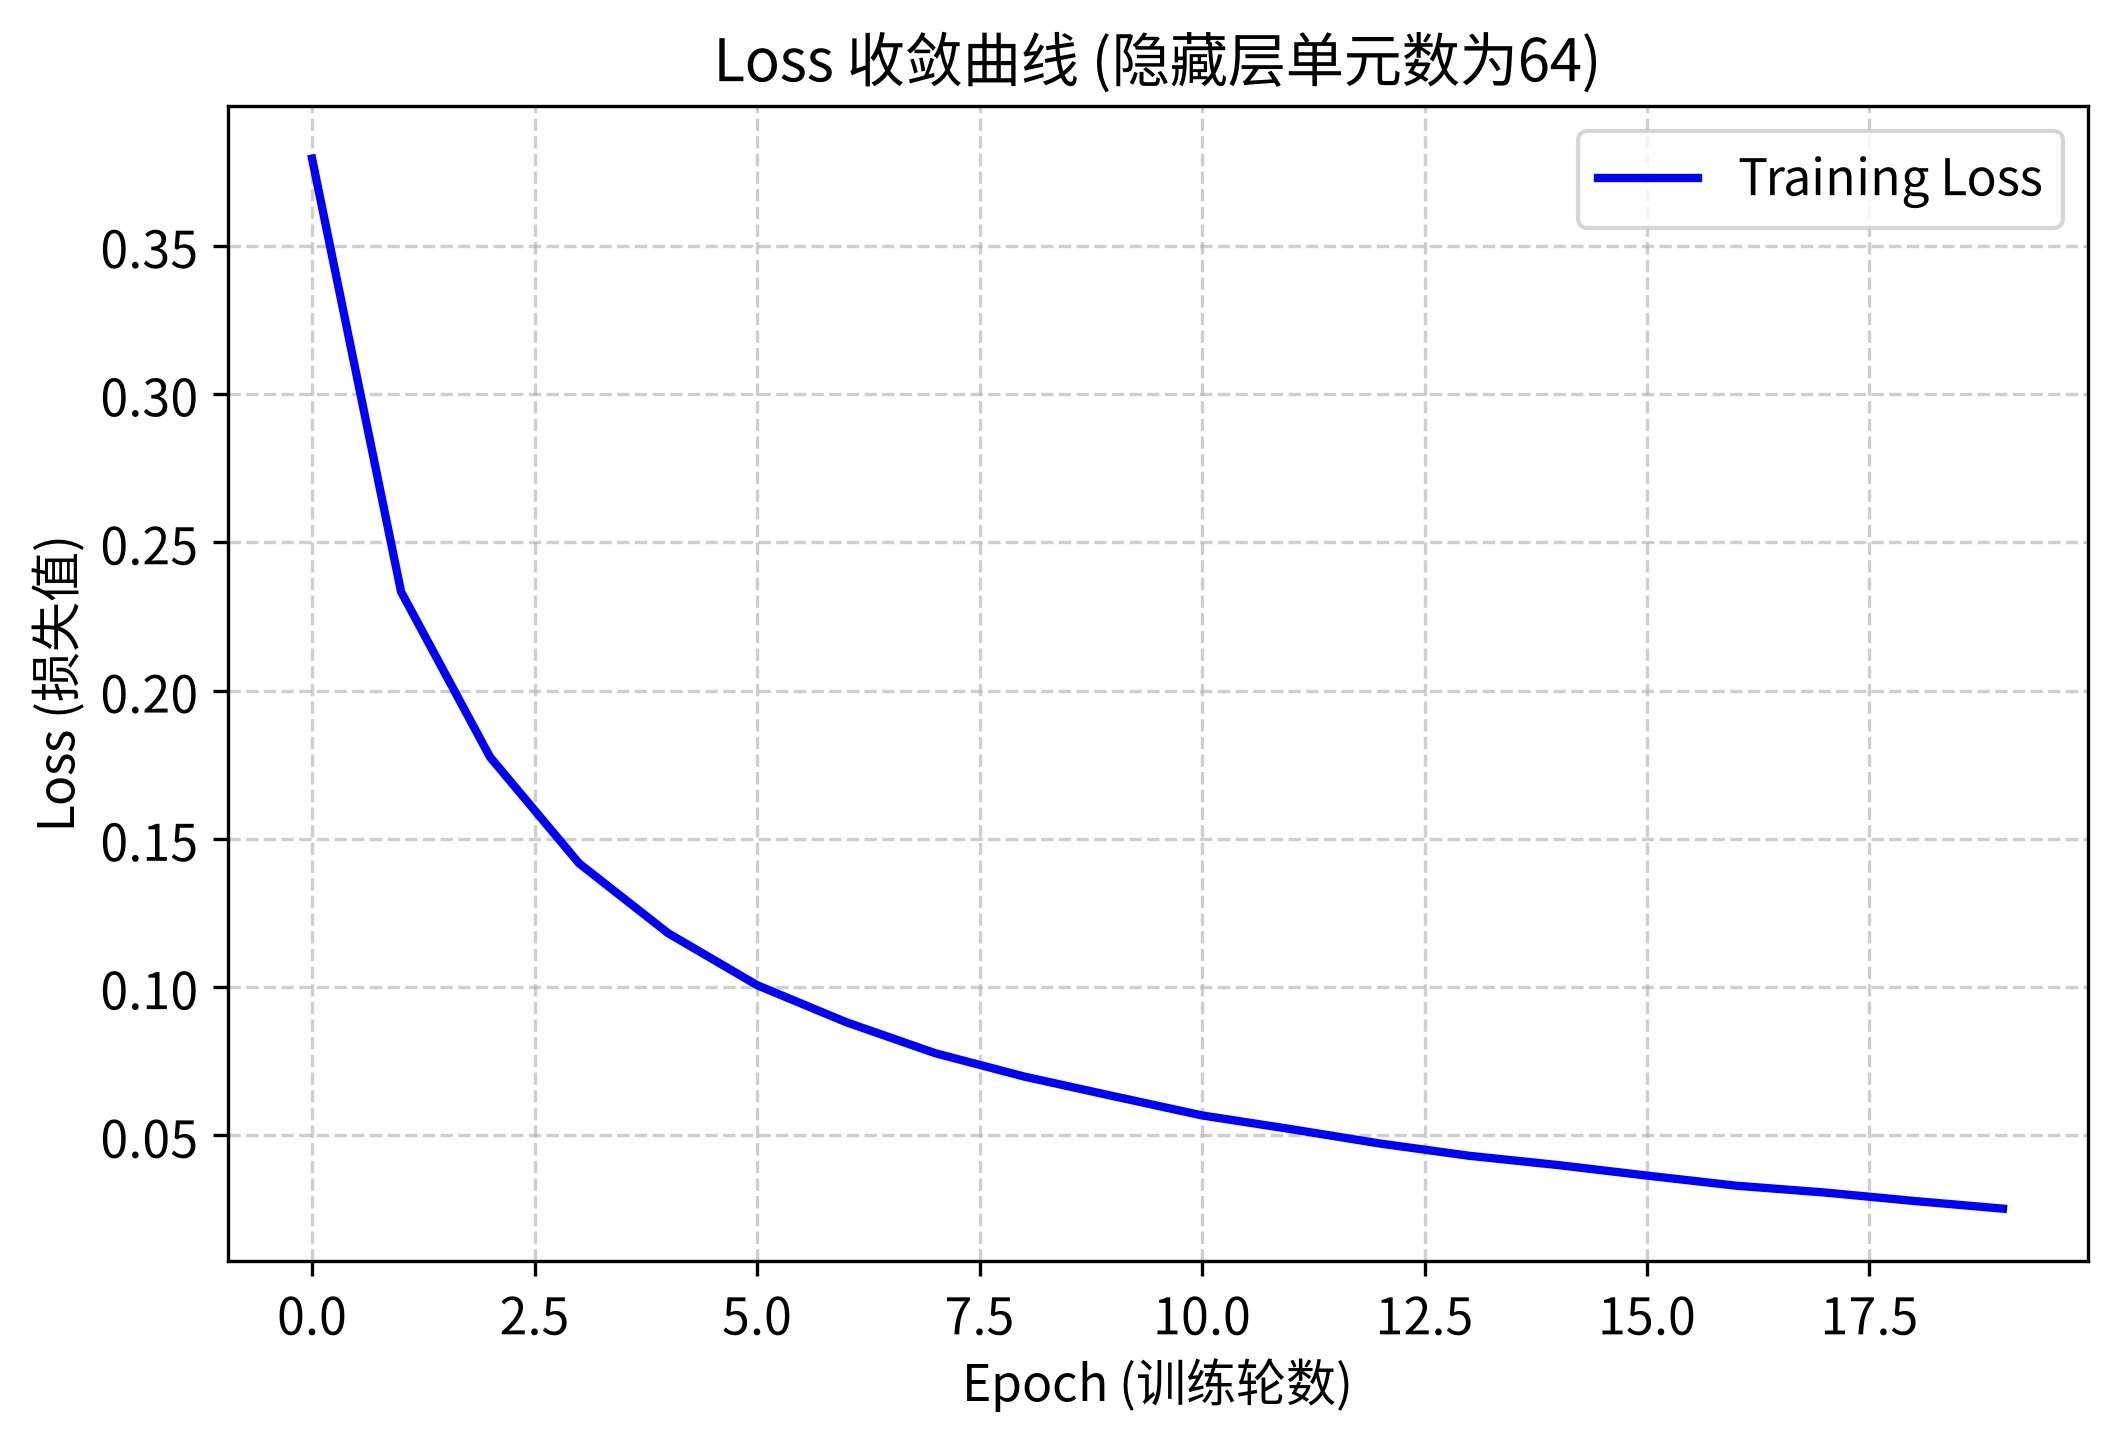

测试集平均损失 (loss): 0.0911
测试集准确率 (Acc): 97.49%  (9749/10000)


In [293]:
model = HiddenNumNet(hidden_num = 64) # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

loss_result = train_model(model, epochs=20, batch = 128)
plot_loss_curve('Loss 收敛曲线 (隐藏层单元数为64)', loss_result)
evaluate_model(model, batch=128)

（2）将隐藏层单元数调整为784

训练进度: 1/20, 训练集loss: 0.2377
训练进度: 2/20, 训练集loss: 0.0954
训练进度: 3/20, 训练集loss: 0.0612
训练进度: 4/20, 训练集loss: 0.0415
训练进度: 5/20, 训练集loss: 0.0295
训练进度: 6/20, 训练集loss: 0.0208
训练进度: 7/20, 训练集loss: 0.0168
训练进度: 8/20, 训练集loss: 0.0116
训练进度: 9/20, 训练集loss: 0.0095
训练进度: 10/20, 训练集loss: 0.0076
训练进度: 11/20, 训练集loss: 0.0060
训练进度: 12/20, 训练集loss: 0.0058
训练进度: 13/20, 训练集loss: 0.0044
训练进度: 14/20, 训练集loss: 0.0042
训练进度: 15/20, 训练集loss: 0.0033
训练进度: 16/20, 训练集loss: 0.0032
训练进度: 17/20, 训练集loss: 0.0032
训练进度: 18/20, 训练集loss: 0.0023
训练进度: 19/20, 训练集loss: 0.0025
训练进度: 20/20, 训练集loss: 0.0018


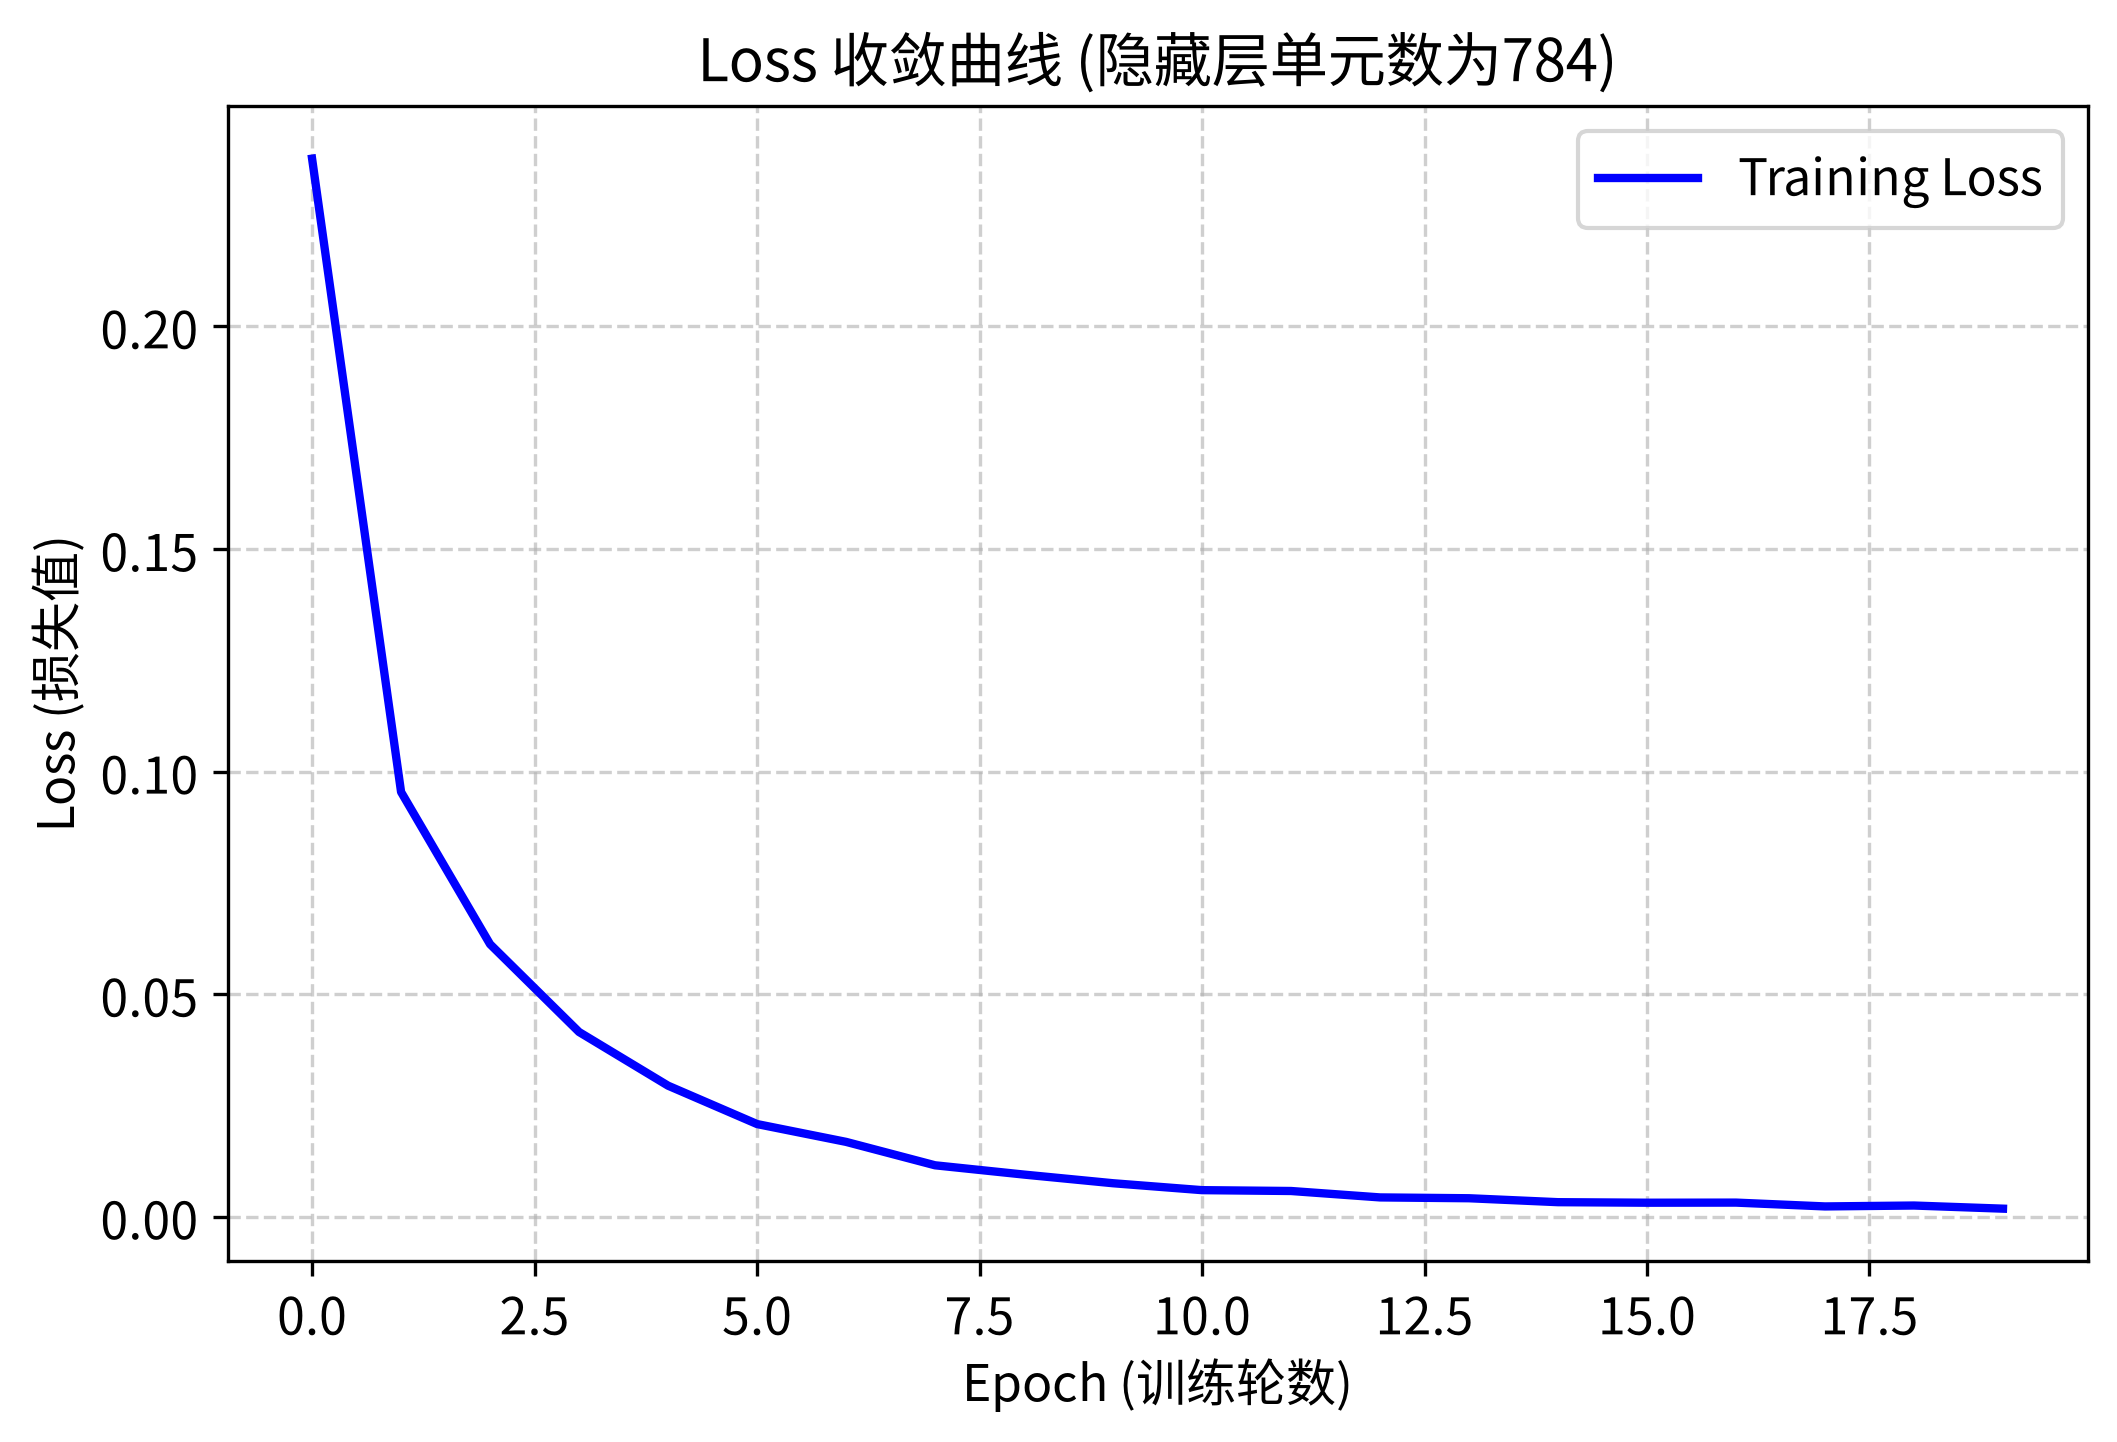

测试集平均损失 (loss): 0.0851
测试集准确率 (Acc): 98.32%  (9832/10000)


In [296]:
model = HiddenNumNet(hidden_num = 784) # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

loss_result = train_model(model, epochs=20, batch = 128)
plot_loss_curve('Loss 收敛曲线 (隐藏层单元数为784)', loss_result)
evaluate_model(model, batch=128)

##### 2.3 训练轮次epoch与批次大小batch
（1）调大训练轮次为30

训练进度: 1/30, 训练集loss: 0.2508
训练进度: 2/30, 训练集loss: 0.1060
训练进度: 3/30, 训练集loss: 0.0700
训练进度: 4/30, 训练集loss: 0.0496
训练进度: 5/30, 训练集loss: 0.0364
训练进度: 6/30, 训练集loss: 0.0265
训练进度: 7/30, 训练集loss: 0.0214
训练进度: 8/30, 训练集loss: 0.0156
训练进度: 9/30, 训练集loss: 0.0124
训练进度: 10/30, 训练集loss: 0.0094
训练进度: 11/30, 训练集loss: 0.0077
训练进度: 12/30, 训练集loss: 0.0067
训练进度: 13/30, 训练集loss: 0.0050
训练进度: 14/30, 训练集loss: 0.0039
训练进度: 15/30, 训练集loss: 0.0044
训练进度: 16/30, 训练集loss: 0.0034
训练进度: 17/30, 训练集loss: 0.0026
训练进度: 18/30, 训练集loss: 0.0024
训练进度: 19/30, 训练集loss: 0.0026
训练进度: 20/30, 训练集loss: 0.0021
训练进度: 21/30, 训练集loss: 0.0021
训练进度: 22/30, 训练集loss: 0.0022
训练进度: 23/30, 训练集loss: 0.0018
训练进度: 24/30, 训练集loss: 0.0017
训练进度: 25/30, 训练集loss: 0.0009
训练进度: 26/30, 训练集loss: 0.0015
训练进度: 27/30, 训练集loss: 0.0017
训练进度: 28/30, 训练集loss: 0.0010
训练进度: 29/30, 训练集loss: 0.0015
训练进度: 30/30, 训练集loss: 0.0012


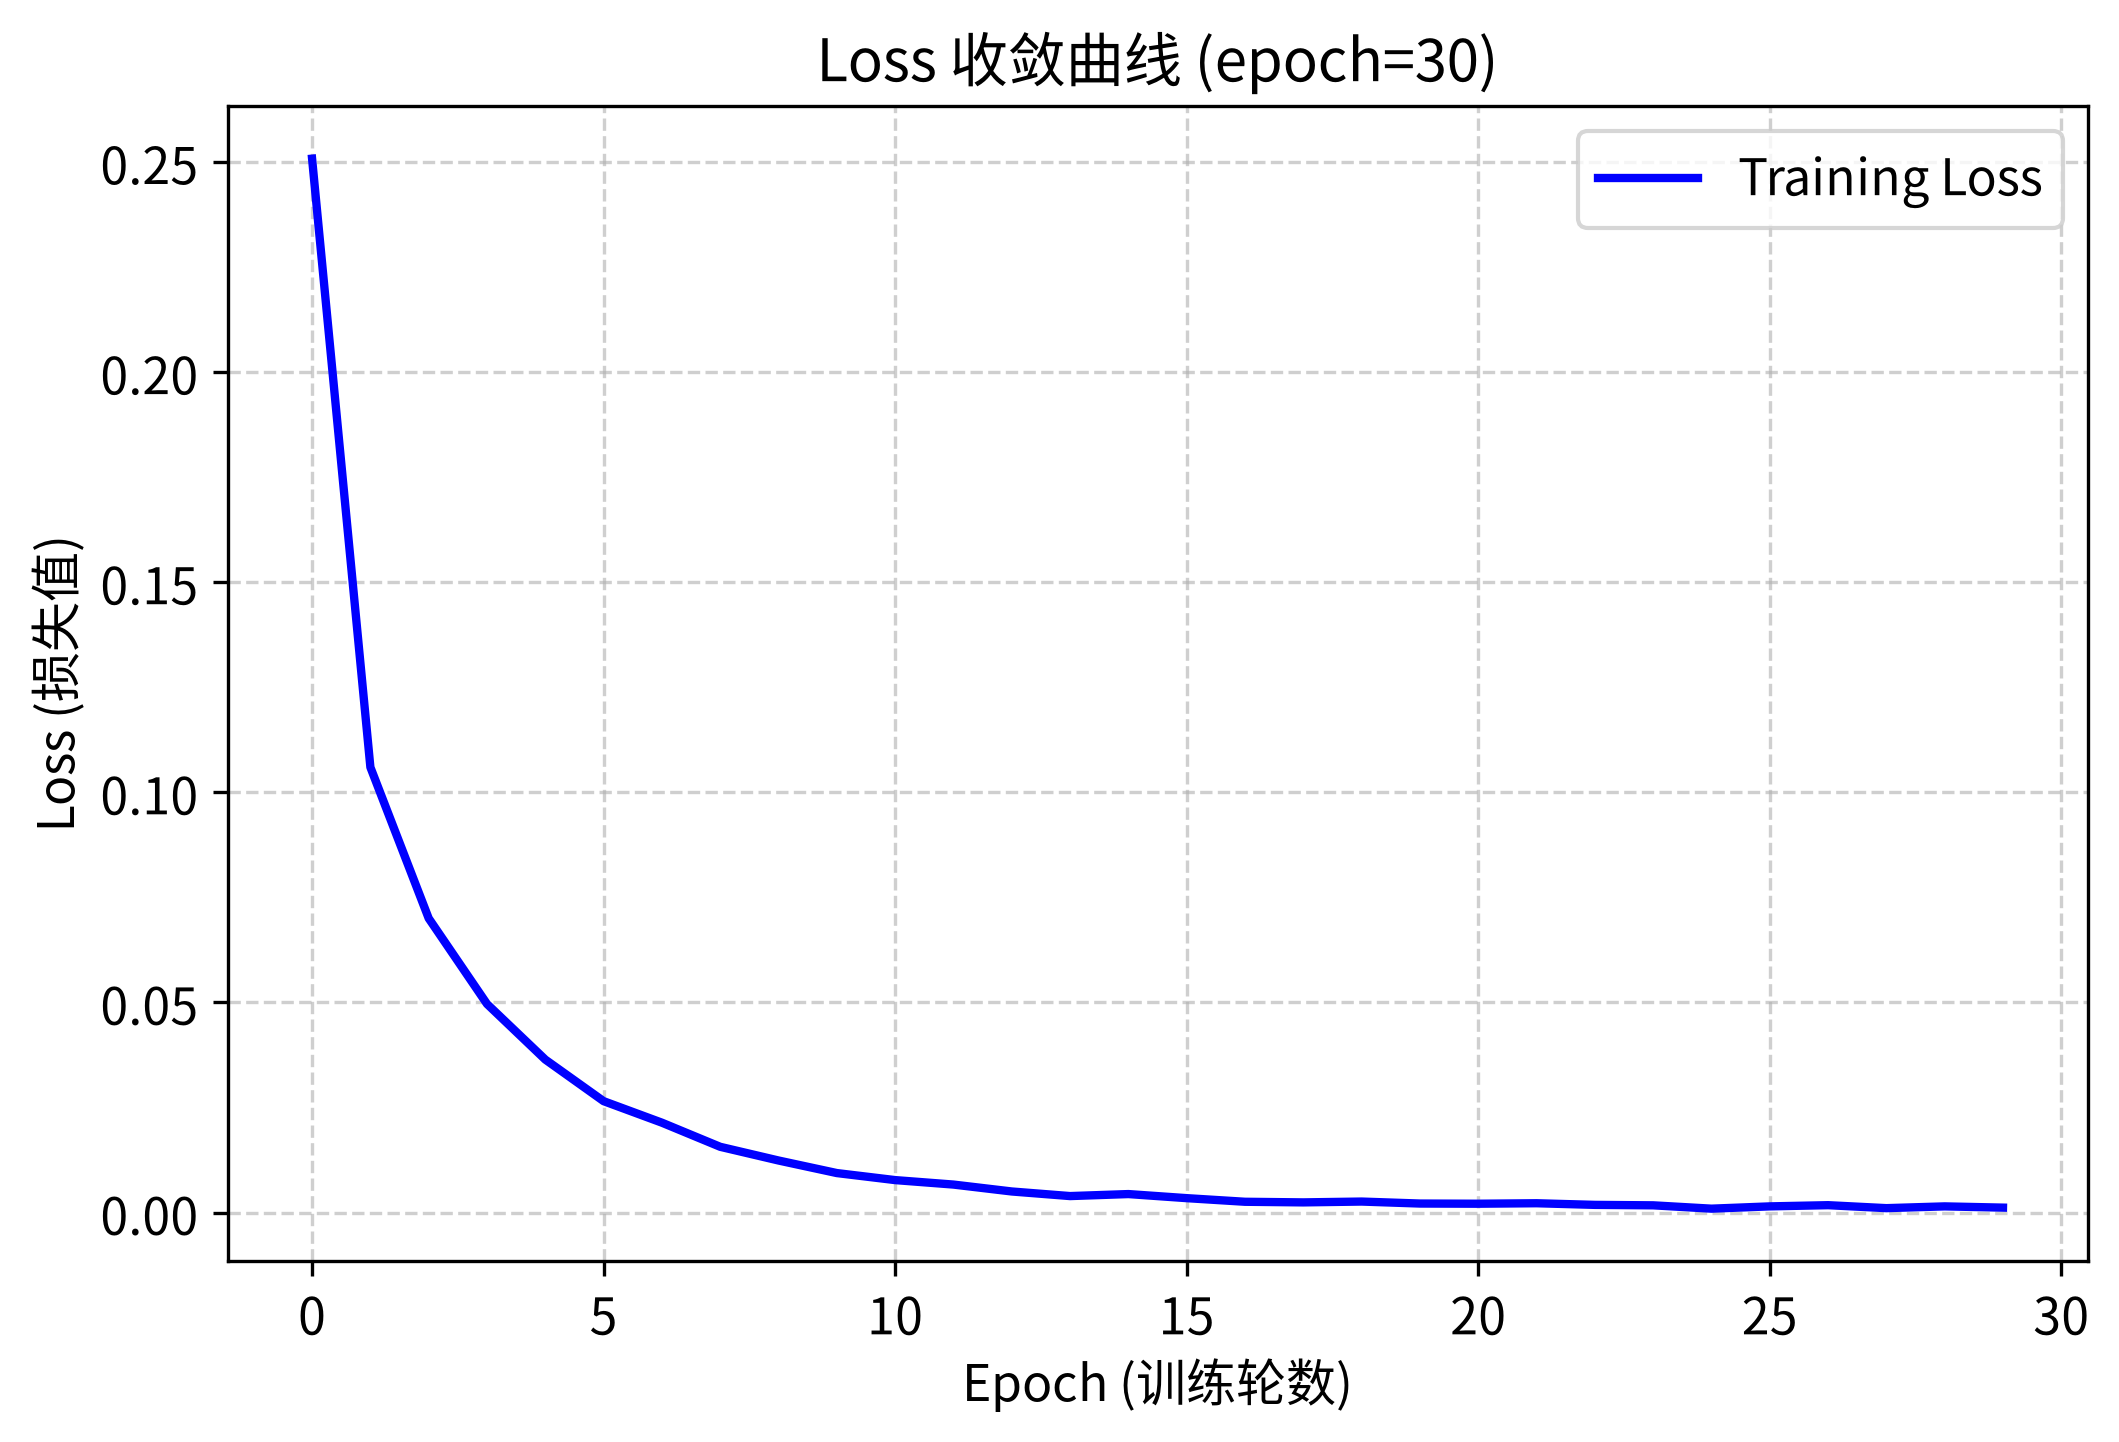

测试集平均损失 (loss): 0.0952
测试集准确率 (Acc): 98.43%  (9843/10000)


In [299]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

loss_result = train_model(model, epochs=30, batch = 128)
plot_loss_curve('Loss 收敛曲线 (epoch=30)', loss_result)
evaluate_model(model, batch=128)

（2）调小训练轮次为10

训练进度: 1/10, 训练集loss: 0.2509
训练进度: 2/10, 训练集loss: 0.1062
训练进度: 3/10, 训练集loss: 0.0699
训练进度: 4/10, 训练集loss: 0.0492
训练进度: 5/10, 训练集loss: 0.0364
训练进度: 6/10, 训练集loss: 0.0259
训练进度: 7/10, 训练集loss: 0.0206
训练进度: 8/10, 训练集loss: 0.0145
训练进度: 9/10, 训练集loss: 0.0121
训练进度: 10/10, 训练集loss: 0.0094


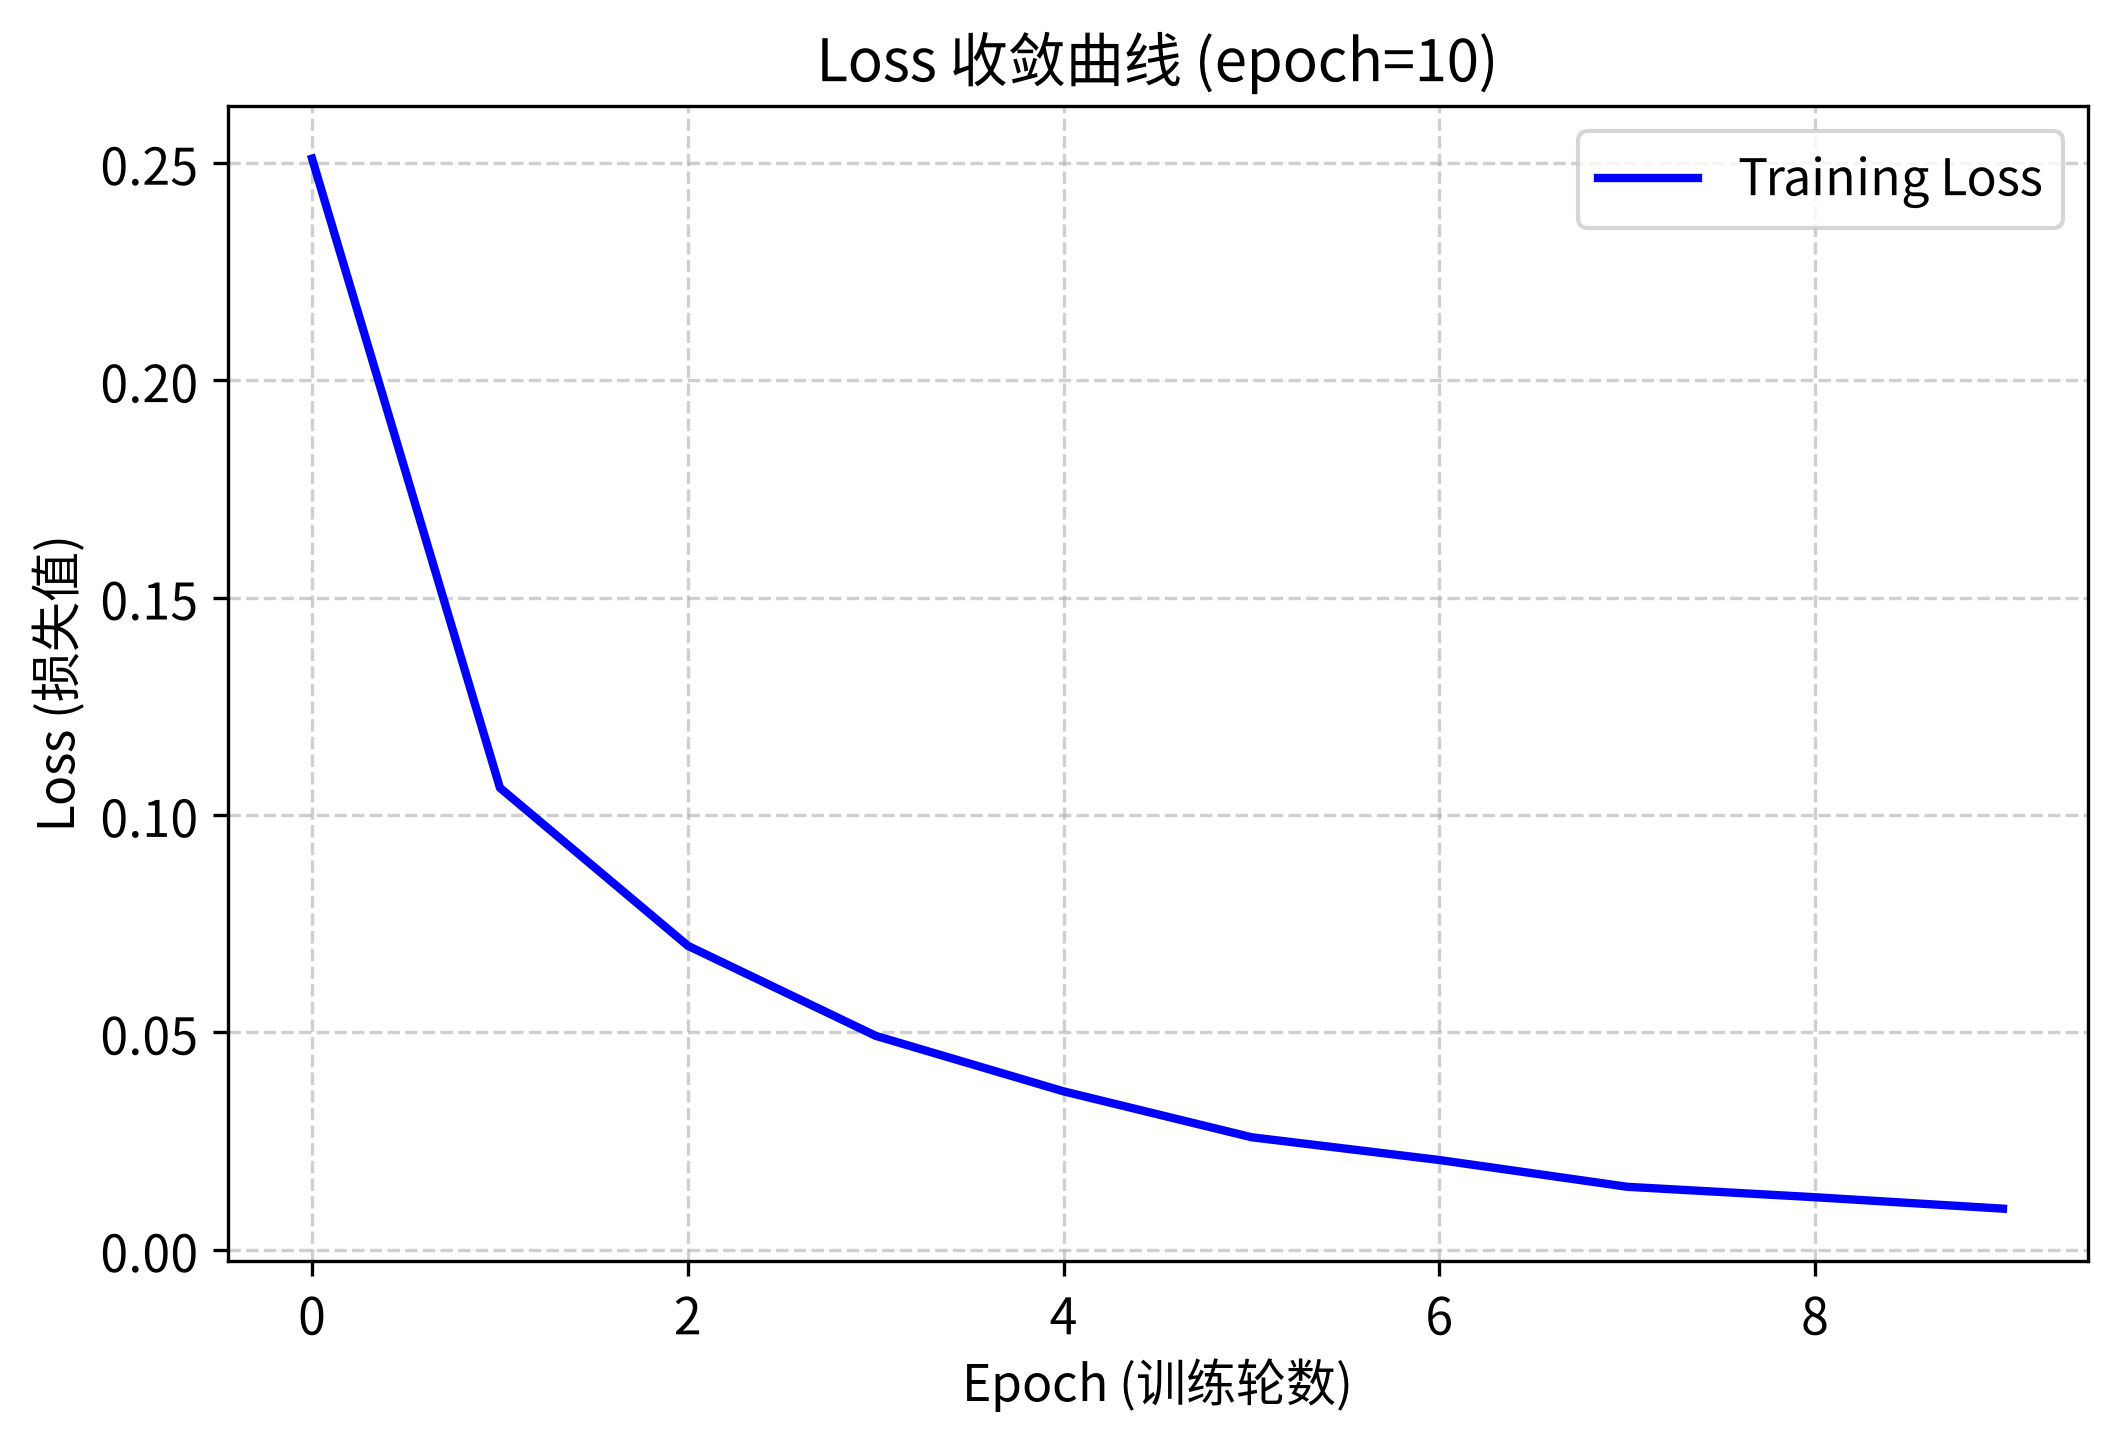

测试集平均损失 (loss): 0.0652
测试集准确率 (Acc): 98.25%  (9825/10000)


In [300]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

loss_result = train_model(model, epochs=10, batch = 128)
plot_loss_curve('Loss 收敛曲线 (epoch=10)', loss_result)
evaluate_model(model, batch=128)

（3）调大批次大小为512

训练进度: 1/20, 训练集loss: 0.3889
训练进度: 2/20, 训练集loss: 0.1716
训练进度: 3/20, 训练集loss: 0.1250
训练进度: 4/20, 训练集loss: 0.0960
训练进度: 5/20, 训练集loss: 0.0774
训练进度: 6/20, 训练集loss: 0.0612
训练进度: 7/20, 训练集loss: 0.0511
训练进度: 8/20, 训练集loss: 0.0417
训练进度: 9/20, 训练集loss: 0.0356
训练进度: 10/20, 训练集loss: 0.0316
训练进度: 11/20, 训练集loss: 0.0236
训练进度: 12/20, 训练集loss: 0.0196
训练进度: 13/20, 训练集loss: 0.0171
训练进度: 14/20, 训练集loss: 0.0138
训练进度: 15/20, 训练集loss: 0.0118
训练进度: 16/20, 训练集loss: 0.0102
训练进度: 17/20, 训练集loss: 0.0078
训练进度: 18/20, 训练集loss: 0.0073
训练进度: 19/20, 训练集loss: 0.0104
训练进度: 20/20, 训练集loss: 0.0049


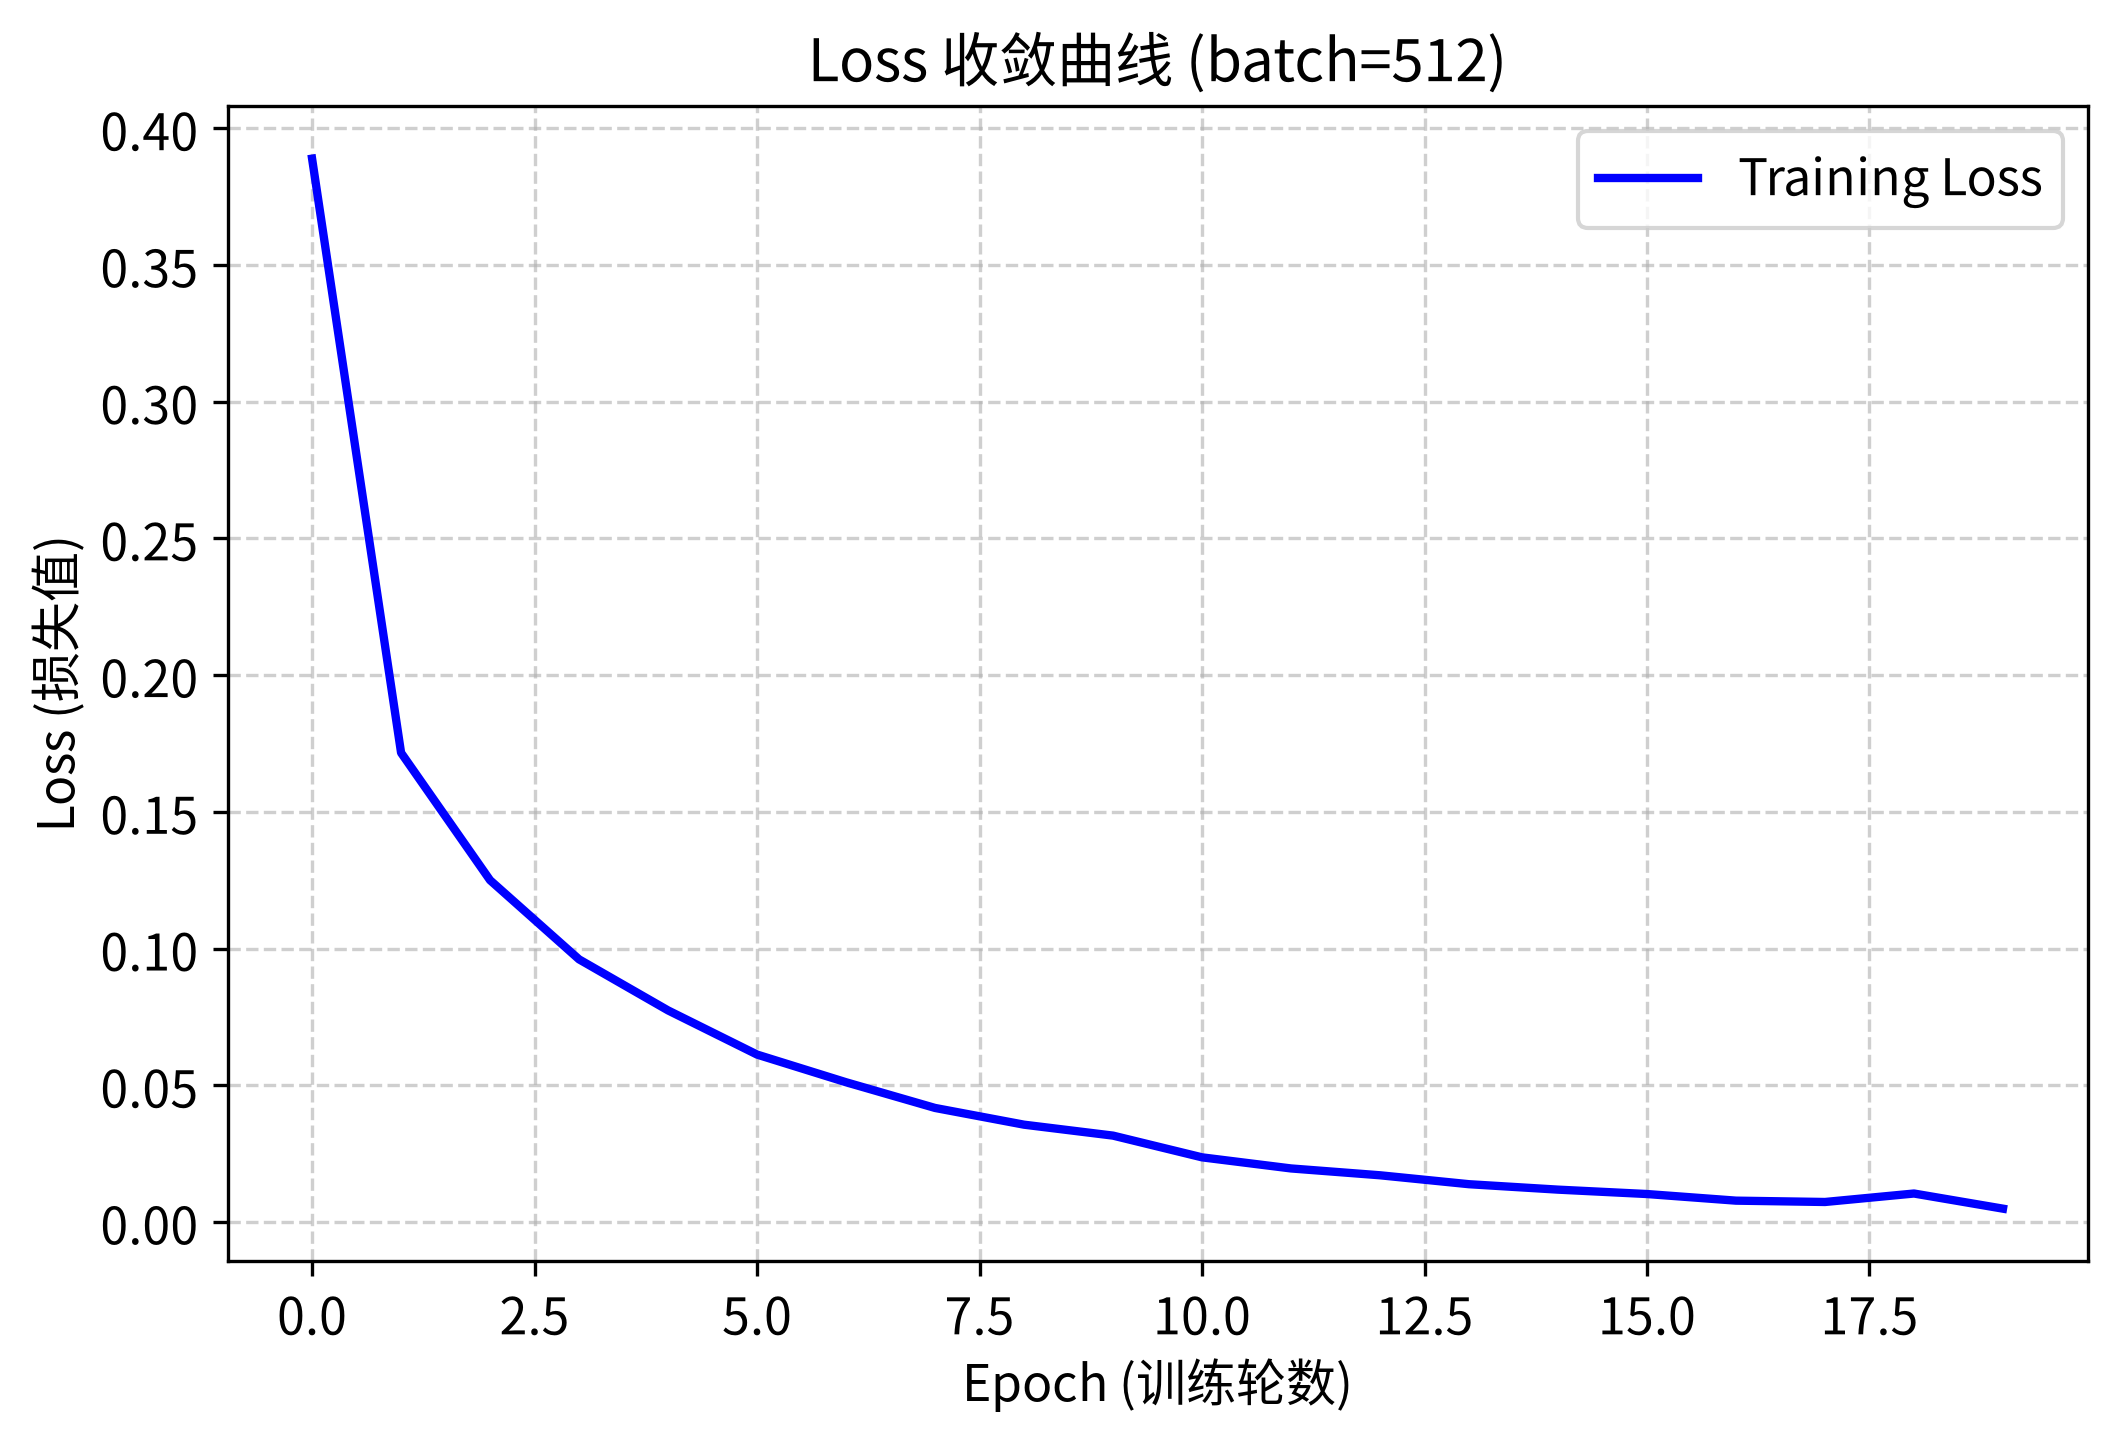

测试集平均损失 (loss): 0.0707
测试集准确率 (Acc): 98.13%  (9813/10000)


In [302]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

loss_result = train_model(model, epochs=20, batch = 512)
plot_loss_curve('Loss 收敛曲线 (batch=512)', loss_result)
evaluate_model(model, batch=512)

（4）调小批次大小为32

训练进度: 1/20, 训练集loss: 0.1947
训练进度: 2/20, 训练集loss: 0.0810
训练进度: 3/20, 训练集loss: 0.0525
训练进度: 4/20, 训练集loss: 0.0376
训练进度: 5/20, 训练集loss: 0.0270
训练进度: 6/20, 训练集loss: 0.0210
训练进度: 7/20, 训练集loss: 0.0164
训练进度: 8/20, 训练集loss: 0.0122
训练进度: 9/20, 训练集loss: 0.0106
训练进度: 10/20, 训练集loss: 0.0085
训练进度: 11/20, 训练集loss: 0.0078
训练进度: 12/20, 训练集loss: 0.0066
训练进度: 13/20, 训练集loss: 0.0056
训练进度: 14/20, 训练集loss: 0.0050
训练进度: 15/20, 训练集loss: 0.0047
训练进度: 16/20, 训练集loss: 0.0036
训练进度: 17/20, 训练集loss: 0.0031
训练进度: 18/20, 训练集loss: 0.0038
训练进度: 19/20, 训练集loss: 0.0036
训练进度: 20/20, 训练集loss: 0.0032


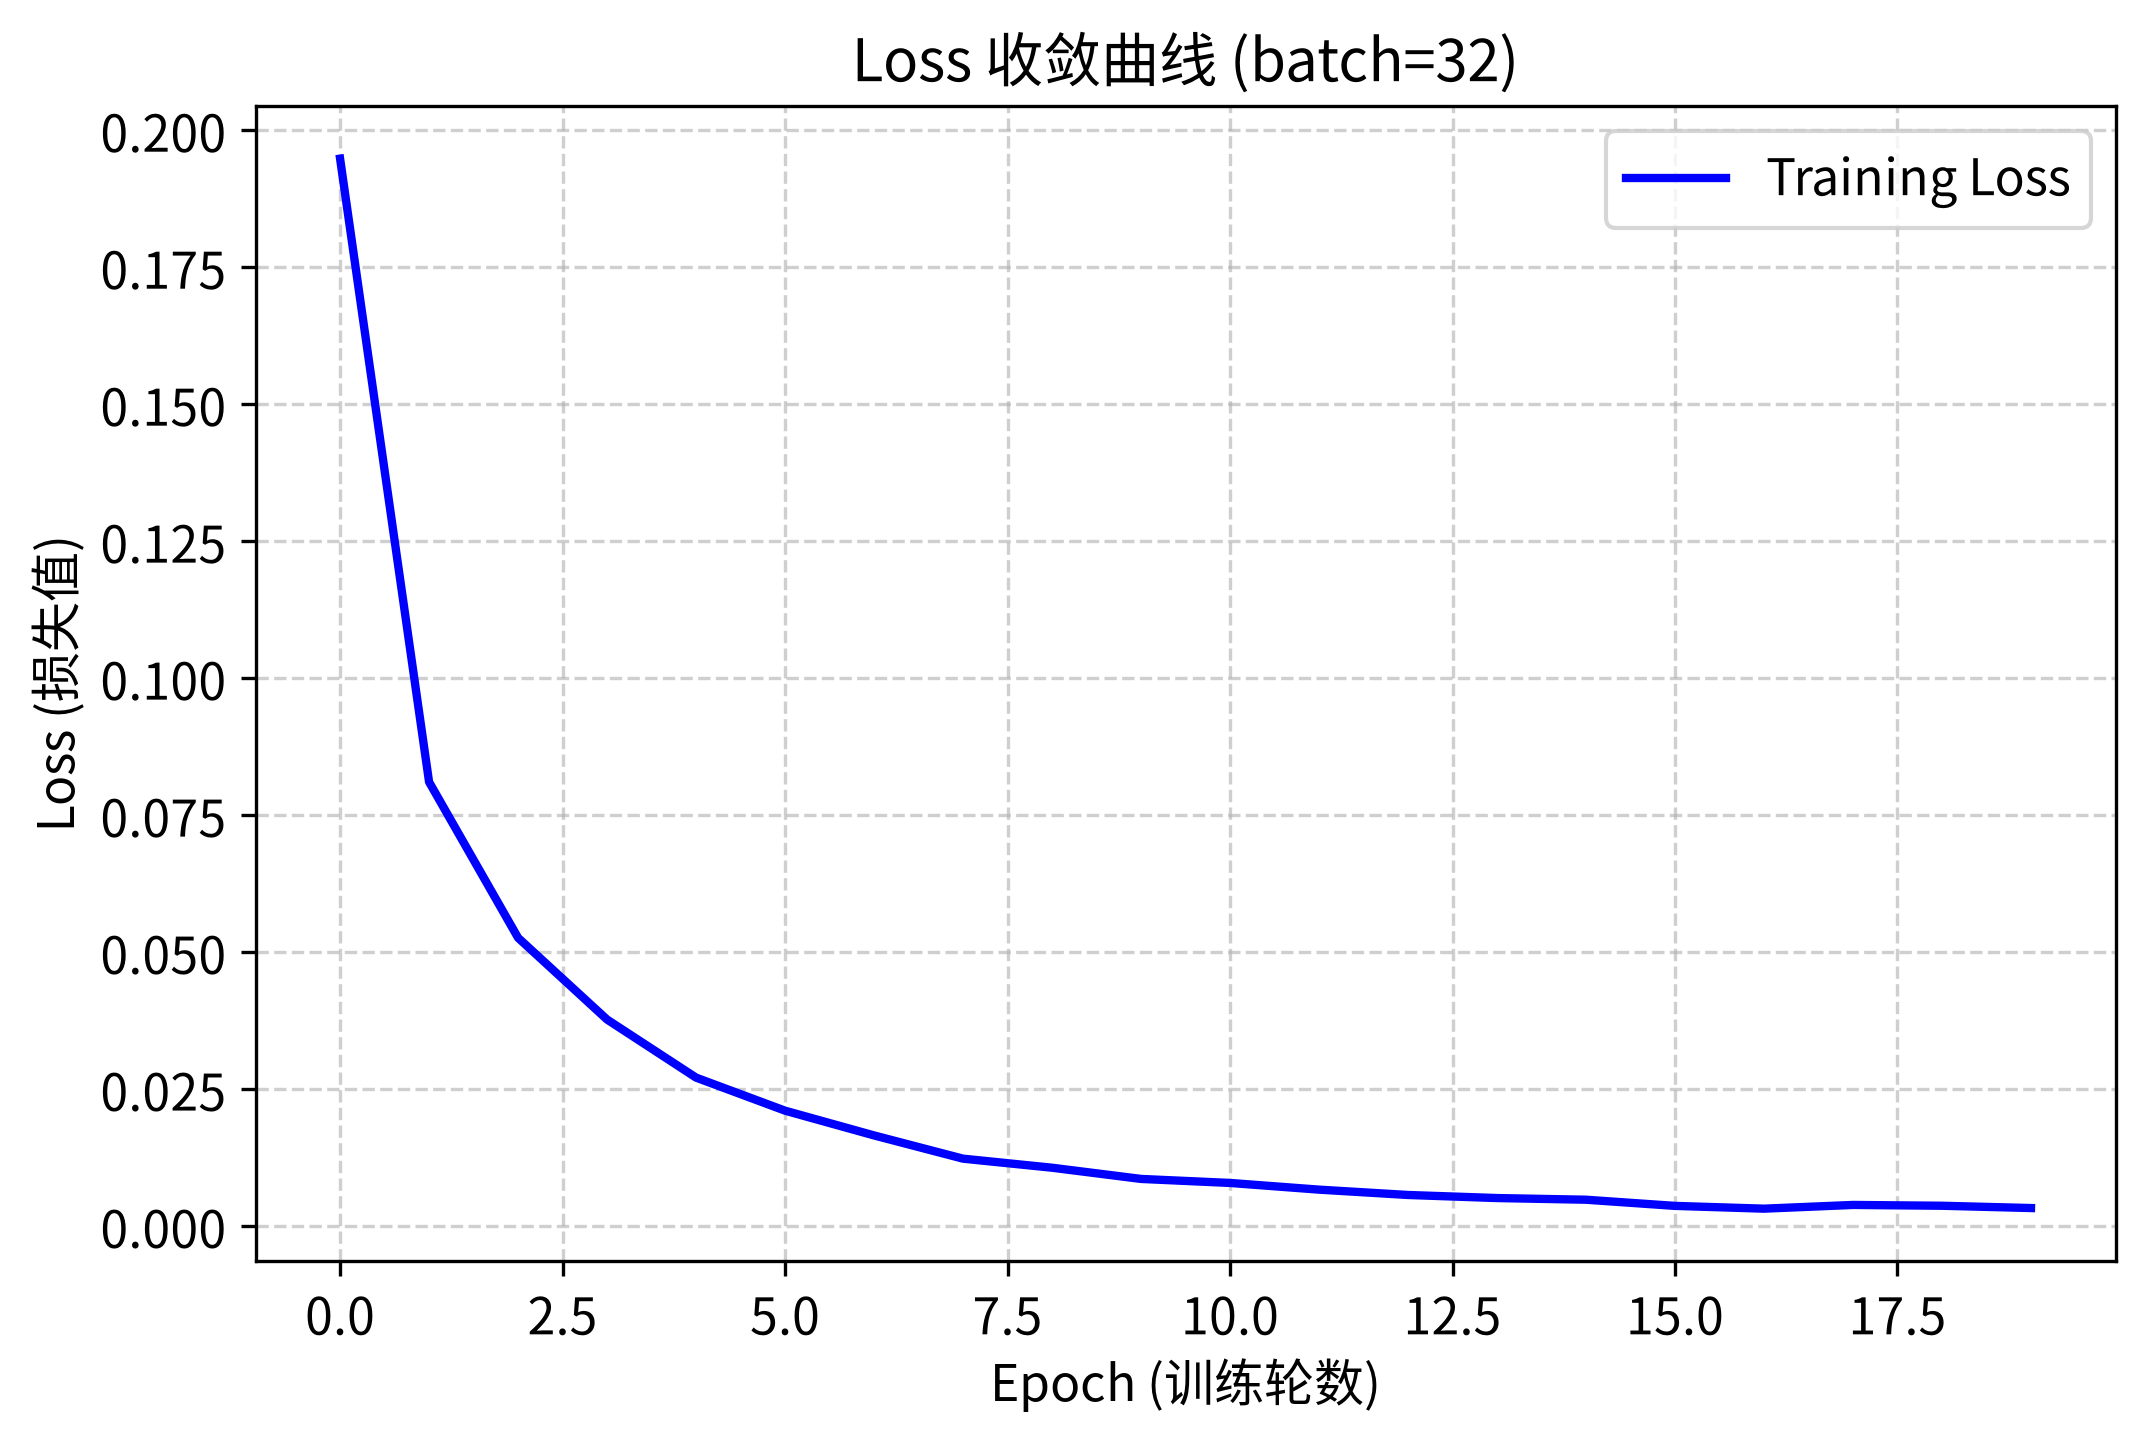

测试集平均损失 (loss): 0.1332
测试集准确率 (Acc): 98.21%  (9821/10000)


In [303]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

loss_result = train_model(model, epochs=20, batch = 32)
plot_loss_curve('Loss 收敛曲线 (batch=32)', loss_result)
evaluate_model(model, batch=32)